## 1️⃣ Install & Import Libraries

In [ ]:
# Install packages not pre-installed on Colab
!pip install -q lime shap wordcloud xgboost streamlit pyngrok

In [ ]:
# Core libraries
import re
import os
import warnings
import numpy as np
import pandas as pd
from collections import Counter

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)

# Explainability
from lime.lime_text import LimeTextExplainer
import shap

# Model persistence
import joblib

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

print("✅ All libraries imported successfully")

✅ All libraries imported successfully


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import urllib.request
import os

# Download Noto Sans Tamil directly
font_url = "https://github.com/google/fonts/raw/main/ofl/notosanstamil/NotoSansTamil%5Bwdth%2Cwght%5D.ttf"
font_path = "/content/NotoSansTamil.ttf"

urllib.request.urlretrieve(font_url, font_path)

# Register font
fm.fontManager.addfont(font_path)

# Create font properties
tamil_font = fm.FontProperties(fname=font_path)

# Set Matplotlib default font
plt.rcParams["font.family"] = tamil_font.get_name()

print("Tamil font loaded successfully!")
print("Font:", tamil_font.get_name())

Tamil font loaded successfully!
Font: Noto Sans Tamil


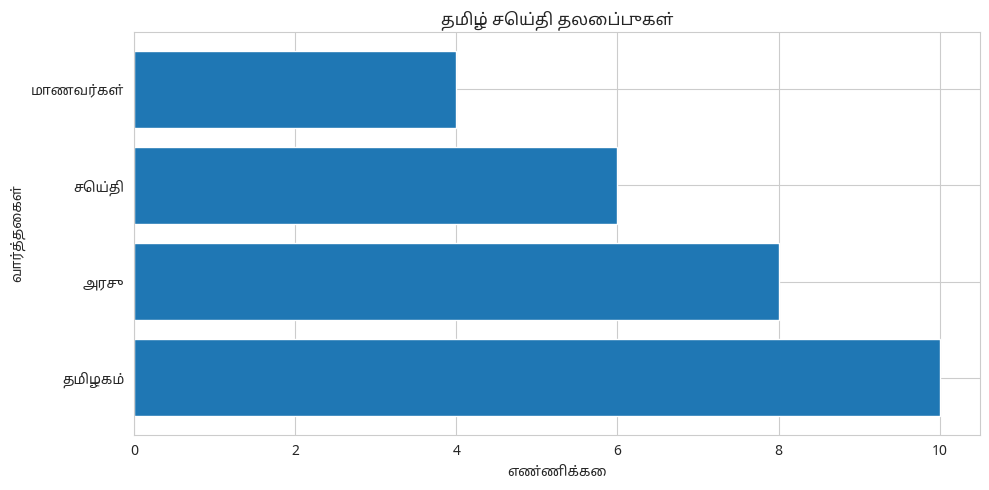

In [ ]:
plt.figure(figsize=(10, 5))

plt.barh(
    ["தமிழகம்", "அரசு", "செய்தி", "மாணவர்கள்"],
    [10, 8, 6, 4]
)

plt.title("தமிழ் செய்தி தலைப்புகள்")
plt.xlabel("எண்ணிக்கை")
plt.ylabel("வார்த்தைகள்")

plt.tight_layout()
plt.show()

## 2️⃣ Load Dataset

Upload `Tamil-News-Headlines.csv` when prompted (works in Google Colab). If you already have the file in your Colab working directory or Google Drive, edit the path accordingly.

In [ ]:
try:
    from google.colab import files
    print("Please upload 'Tamil-News-Headlines.csv'")
    uploaded = files.upload()
    csv_path = list(uploaded.keys())[0]
except ImportError:
    # Not running on Colab — edit this path to point to your local file
    csv_path = "Tamil-News-Headlines.csv"

df = pd.read_csv(csv_path)
print("Dataset shape:", df.shape)
df.head()

Please upload 'Tamil-News-Headlines.csv'


Saving Tamil-News-Headlines.csv to Tamil-News-Headlines (1).csv
Dataset shape: (5226, 7)


,Unnamed: 0,English Version,Label,News,Author,Date,Authenticity
0,0,Additional charge for users who share password...,tech,பாஸ்வேர்டை பகிரும் பயனர்களிடம் கூடுதல் கட்டணம...,செய்திப்பிரிவு,19-Oct-22,0
1,1,Production of 'AK-203' guns in India by the en...,tech,இந்தியாவில் நடப்பு ஆண்டின் இறுதிக்குள் ‘ஏகே-2...,செய்திப்பிரிவு,18-Oct-22,0
2,2,Moto E22s smartphone launched in India at a bu...,tech,பட்ஜெட் விலையில் மோட்டோ E22s ஸ்மார்ட்போன் இந்...,செய்திப்பிரிவு,17-Oct-22,0
3,3,Let's make Kalam's last dream come true,tech,கலாம் கண்ட கடைசி கனவை நனவாக்குவோம்,செய்திப்பிரிவு,15-Oct-22,0
4,4,Redmi A1+ smartphone launched in India at a bu...,tech,பட்ஜெட் விலையில் ரெட்மி ஏ1+ ஸ்மார்ட்போன் இந்த...,செய்திப்பிரிவு,14-Oct-22,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5226 entries, 0 to 5225
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Unnamed: 0       5226 non-null   int64 
 1   English Version  5226 non-null   object
 2   Label            5226 non-null   object
 3   News             5226 non-null   object
 4   Author           5148 non-null   object
 5   Date             5226 non-null   object
 6   Authenticity     5226 non-null   int64 
dtypes: int64(2), object(5)
memory usage: 285.9+ KB


In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,5226.0,NaN,NaN,NaN,1336.431114,795.826296,0.0,653.0,1311.5,1982.75,2948.0
English Version,5226,5174,Do you know Sethi?,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Label,5226,5,politics,1674,NaN,NaN,NaN,NaN,NaN,NaN,NaN
News,5226,5178,சேதி தெரியுமா?,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Author,5148,930,செய்திப்பிரிவு,1337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,5226,3695,19-Oct-22,144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Authenticity,5226.0,NaN,NaN,NaN,0.5553,0.49698,0.0,0.0,1.0,1.0,1.0


## 3️⃣ Data Preprocessing

Steps performed:
- Drop the unused index column
- Check & handle missing values
- Clean the Tamil headline text (remove URLs, English words, digits, punctuation — keep only Tamil Unicode characters)
- Remove empty rows created after cleaning
- Remove duplicate headlines
- Build a Tamil stopword list (used for EDA word clouds)


In [ ]:
# Drop unused index column if present
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("Missing values per column:")
print(df.isnull().sum())

# Author has some missing values but isn't used for modelling — safe to keep/drop as needed
df['Author'] = df['Author'].fillna('Unknown')

Missing values per column:
English Version     0
Label               0
News                0
Author             78
Date                0
Authenticity        0
dtype: int64


> ⚠️ **Verify the target encoding before trusting it.** Column names like `Authenticity`
> can be misleading — always confirm what each numeric value actually means by reading
> sample headlines, don't assume `1 = Real` / `0 = Fake` (or vice-versa) from the name alone.
> In this dataset, headlines under `Authenticity = 1` are overwhelmingly quote-style viral
> claims (classic fact-check bait), while `Authenticity = 0` headlines are routine news
> reporting — i.e. **`1 = Fake`, `0 = Real`**. The cell below checks this quantitatively.

In [ ]:
# Sanity-check the label encoding: viral misinformation headlines are typically
# framed as quoted claims ("X law says...", "Person Y admitted..."), while routine
# news reporting rarely is. A large gap here confirms which numeric value means what.
quote_rate = df.groupby('Authenticity')['News'].apply(lambda s: s.str.contains('"').mean())
print("Share of headlines containing quote marks, by Authenticity value:")
print(quote_rate)
print()
print("--- Sample headlines where Authenticity == 1 ---")
for t in df[df['Authenticity'] == 1]['News'].sample(3, random_state=1):
    print("-", t.strip()[:100])
print()
print("--- Sample headlines where Authenticity == 0 ---")
for t in df[df['Authenticity'] == 0]['News'].sample(3, random_state=1):
    print("-", t.strip()[:100])

Share of headlines containing quote marks, by Authenticity value:
Authenticity
0    0.014630
1    0.708477
Name: News, dtype: float64

--- Sample headlines where Authenticity == 1 ---
- 2020 டிசம்பரில் பூமி 6 நாட்களுக்கு இருளில் இருக்கும் என நாசா உறுதி செய்துள்ளது.
- எச்.ஐ.வி வைரஸைக் கண்டறிய உதவிய டாக்டர் ராபர்ட் காலோ, "ஆப்பிரிக்க இனத்தை அழிக்க ஒரு ரகசிய ஆயுதமாக எச்
- ஒரு CDC அறிக்கை, "முகமூடிகளை அணிந்தவர்கள், உண்மையில் தங்கள் முகமூடிகளில் வைரஸை 'சேகரிக்கிறார்கள்' என

--- Sample headlines where Authenticity == 0 ---
- மகளிர் ஆசிய கோப்பை டி 20 | இந்தியா – பாகிஸ்தான் இன்று...
- தலைமையாசிரியர்களுக்கு தலைமைப்பண்பு பயிற்சி: மதுரையில் நடக்கிறது
- ஆப்பிள் ஈவென்ட் 2022 ஹைலைட்ஸ் | ஐபோன் 14 சீரிஸ் போன்கள், ஆப்பிள்...


In [ ]:
def clean_tamil_text(text):
    """Clean a Tamil headline: remove URLs, English words/numbers,
    punctuation, and extra whitespace — keep only Tamil Unicode characters."""
    text = str(text)
    text = re.sub(r'http\S+|www\S+', ' ', text)          # URLs
    text = re.sub(r'[a-zA-Z0-9]+', ' ', text)             # English words / numbers
    text = re.sub(r'[^\u0B80-\u0BFF\s]', ' ', text)      # keep only Tamil Unicode block
    text = re.sub(r'\s+', ' ', text).strip()              # collapse whitespace
    return text

df['clean_news'] = df['News'].apply(clean_tamil_text)

# Drop rows that became empty after cleaning (e.g. purely English headlines)
before = len(df)
df = df[df['clean_news'].str.len() > 0].reset_index(drop=True)
print(f"Dropped {before - len(df)} empty rows after cleaning")

# Drop duplicate headlines
before = len(df)
df = df.drop_duplicates(subset='clean_news').reset_index(drop=True)
print(f"Dropped {before - len(df)} duplicate rows")

df[['News', 'clean_news', 'Authenticity']].head(10)

Dropped 1 empty rows after cleaning
Dropped 58 duplicate rows


,News,clean_news,Authenticity
0,பாஸ்வேர்டை பகிரும் பயனர்களிடம் கூடுதல் கட்டணம...,பாஸ்வேர்டை பகிரும் பயனர்களிடம் கூடுதல் கட்டணம்...,0
1,இந்தியாவில் நடப்பு ஆண்டின் இறுதிக்குள் ‘ஏகே-2...,இந்தியாவில் நடப்பு ஆண்டின் இறுதிக்குள் ஏகே ரக ...,0
2,பட்ஜெட் விலையில் மோட்டோ E22s ஸ்மார்ட்போன் இந்...,பட்ஜெட் விலையில் மோட்டோ ஸ்மார்ட்போன் இந்தியாவி...,0
3,கலாம் கண்ட கடைசி கனவை நனவாக்குவோம்,கலாம் கண்ட கடைசி கனவை நனவாக்குவோம்,0
4,பட்ஜெட் விலையில் ரெட்மி ஏ1+ ஸ்மார்ட்போன் இந்த...,பட்ஜெட் விலையில் ரெட்மி ஏ ஸ்மார்ட்போன் இந்தியா...,0
5,கூகுள் பிளே பாயிண்ட்ஸ் இந்தியாவில் அறிமுகம் |...,கூகுள் பிளே பாயிண்ட்ஸ் இந்தியாவில் அறிமுகம் டவ...,0
6,நோக்கியா ஜி11 பிளஸ் ஸ்மார்ட்போன் இந்தியாவில் ...,நோக்கியா ஜி பிளஸ் ஸ்மார்ட்போன் இந்தியாவில் அறி...,0
7,ஃபேஸ்புக்கில் தொழில்நுட்ப கோளாறு? - ஃபாலோயர்க...,ஃபேஸ்புக்கில் தொழில்நுட்ப கோளாறு ஃபாலோயர்களை அ...,0
8,5ஜி சாதனங்களில் நவம்பர் மத்தியில் 5ஜி சப்போர்...,ஜி சாதனங்களில் நவம்பர் மத்தியில் ஜி சப்போர்ட் ...,0
9,ஸ்மார்ட்போனில் 5ஜி பயன்படுத்த புதிய சிம் கார்...,ஸ்மார்ட்போனில் ஜி பயன்படுத்த புதிய சிம் கார்டு...,0


In [ ]:
# Small Tamil stopword list — common function words that carry little
# discriminative meaning. Used only for word-cloud / frequency EDA below.
TAMIL_STOPWORDS = set("""
ஒரு என்று கூறுகிறார் மற்றும் இது அது இந்த அந்த என்ன ஆனால் அல்லது
என அவர் அவர்கள் நான் நாம் நீங்கள் இருந்து வரை மீது கீழ் மேலும்
இல்லை ஆம் இருக்கும் இருந்தது செய்ய செய்து கொண்டு உள்ள உள்ளது
தான் தன் இவர் அவை இவை என்பது எனும் போது பின்னர் முன்பு
""".split())

def remove_stopwords(text):
    return ' '.join([w for w in text.split() if w not in TAMIL_STOPWORDS])

df['wordcloud_text'] = df['clean_news'].apply(remove_stopwords)
print("Preprocessing complete. Final dataset shape:", df.shape)

Preprocessing complete. Final dataset shape: (5167, 8)


## 4️⃣ Exploratory Data Analysis (EDA)

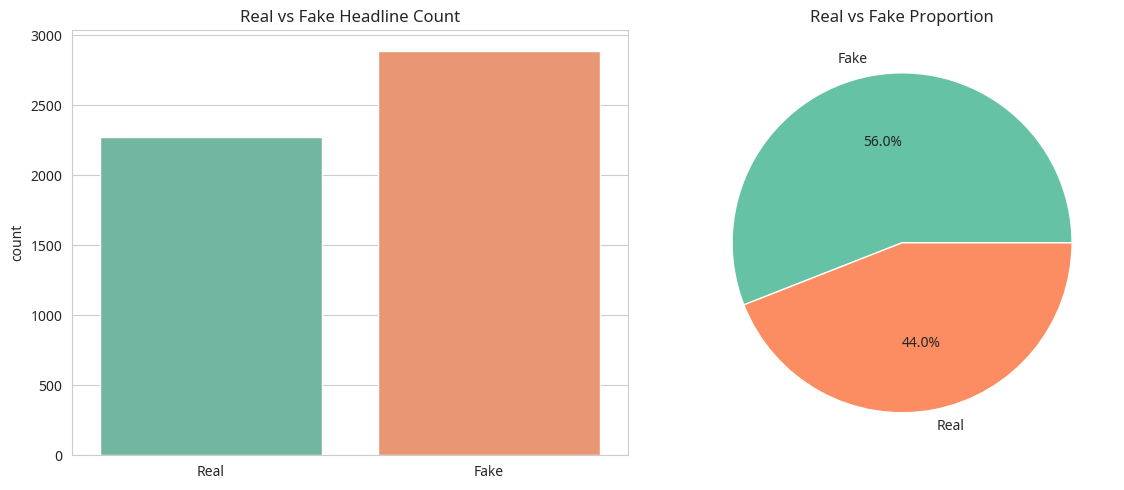

Authenticity_label
Fake    2891
Real    2276
Name: count, dtype: int64


In [ ]:
# Target class distribution: Real (1) vs Fake (0)
label_map = {0: 'Real', 1: 'Fake'}
df['Authenticity_label'] = df['Authenticity'].map(label_map)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(data=df, x='Authenticity_label', hue='Authenticity_label',
              palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Real vs Fake Headline Count')
axes[0].set_xlabel('')

df['Authenticity_label'].value_counts().plot.pie(
    autopct='%1.1f%%', colors=sns.color_palette('Set2'), ax=axes[1])
axes[1].set_ylabel('')
axes[1].set_title('Real vs Fake Proportion')
plt.tight_layout()
plt.show()

print(df['Authenticity_label'].value_counts())

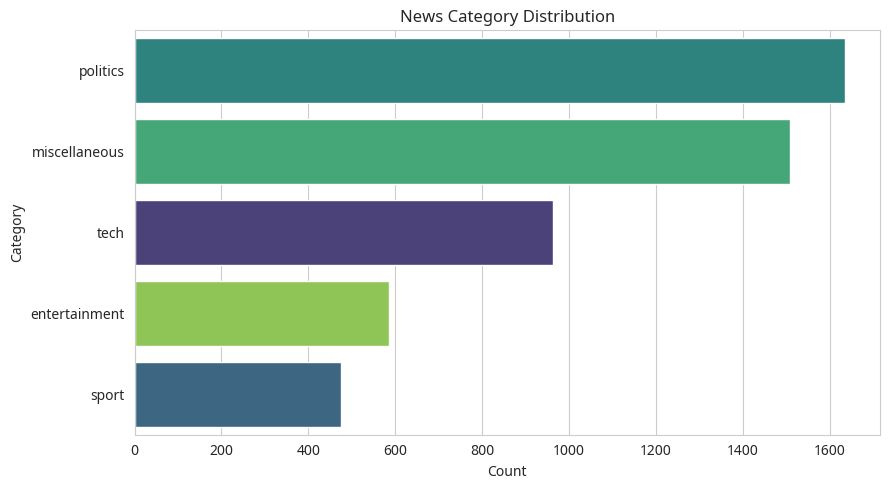

In [ ]:
# News category (Label) distribution
plt.figure(figsize=(9, 5))
order = df['Label'].value_counts().index
sns.countplot(data=df, y='Label', order=order, hue='Label', palette='viridis', legend=False)
plt.title('News Category Distribution')
plt.xlabel('Count')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

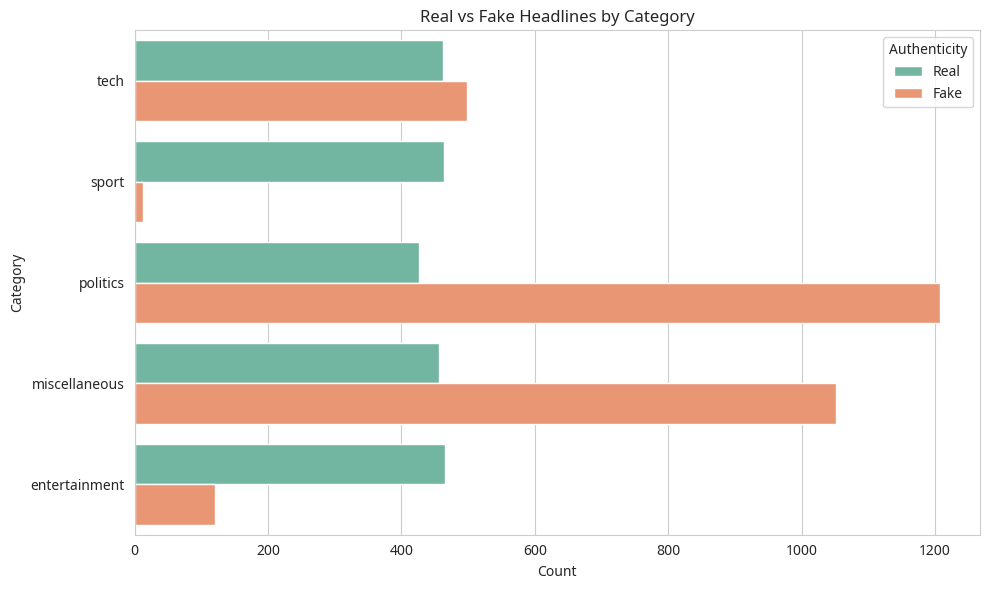

In [ ]:
# Authenticity split within each category
plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='Label', hue='Authenticity_label', palette='Set2')
plt.title('Real vs Fake Headlines by Category')
plt.xlabel('Count')
plt.ylabel('Category')
plt.legend(title='Authenticity')
plt.tight_layout()
plt.show()

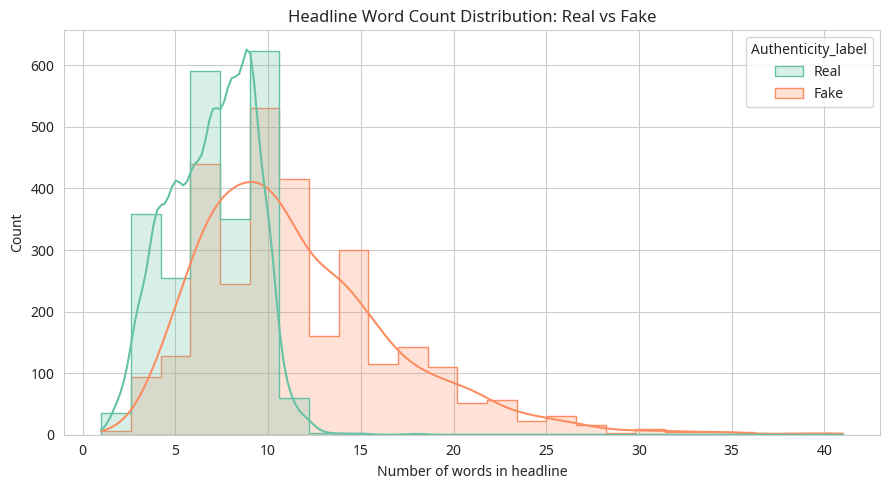

                     count       mean       std  min  25%   50%   75%   max
Authenticity_label                                                         
Fake                2891.0  11.627810  5.424331  1.0  8.0  11.0  14.0  41.0
Real                2276.0   6.978471  2.263319  1.0  5.0   7.0   9.0  18.0


In [ ]:
# Headline length (word count) distribution — Real vs Fake
df['word_count'] = df['clean_news'].apply(lambda x: len(x.split()))

plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='word_count', hue='Authenticity_label',
             bins=25, kde=True, palette='Set2', element='step')
plt.title('Headline Word Count Distribution: Real vs Fake')
plt.xlabel('Number of words in headline')
plt.tight_layout()
plt.show()

print(df.groupby('Authenticity_label')['word_count'].describe())

In [ ]:
# Download a Tamil-supporting font for word cloud rendering
!wget -q -O NotoSansTamil.ttf "https://raw.githubusercontent.com/google/fonts/main/ofl/notosanstamil/NotoSansTamil%5Bwdth%2Cwght%5D.ttf"
print("Font downloaded:", os.path.exists("NotoSansTamil.ttf"))

Font downloaded: True


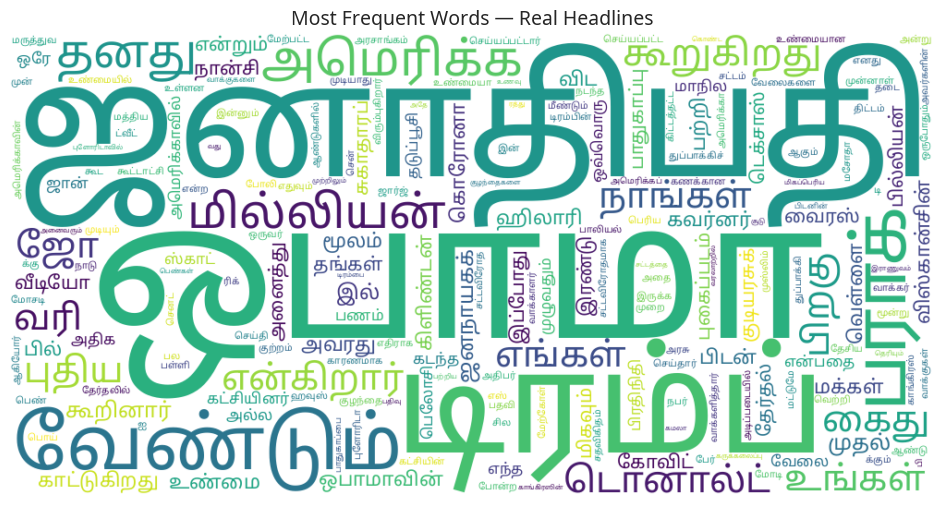

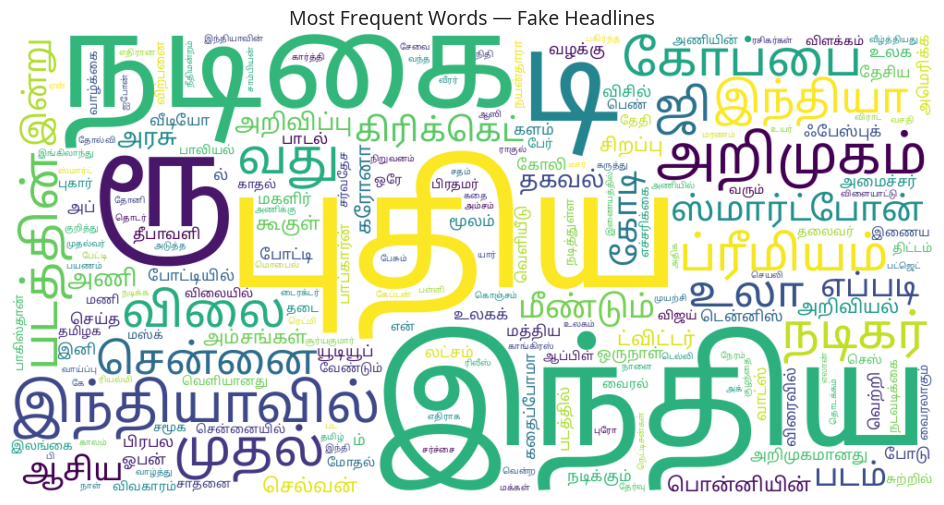

In [ ]:
def plot_wordcloud(text_series, title):
    """Build a word cloud from whitespace-tokenised Tamil text.
    (WordCloud's default regex tokenizer breaks Tamil combining
    characters, so we compute frequencies manually.)"""
    words = ' '.join(text_series).split()
    freq = Counter(words)
    wc = WordCloud(font_path='NotoSansTamil.ttf', width=1000, height=500,
                    background_color='white', colormap='viridis').generate_from_frequencies(freq)
    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(title, fontsize=14)
    plt.show()

plot_wordcloud(df[df['Authenticity'] == 1]['wordcloud_text'], 'Most Frequent Words — Real Headlines')
plot_wordcloud(df[df['Authenticity'] == 0]['wordcloud_text'], 'Most Frequent Words — Fake Headlines')

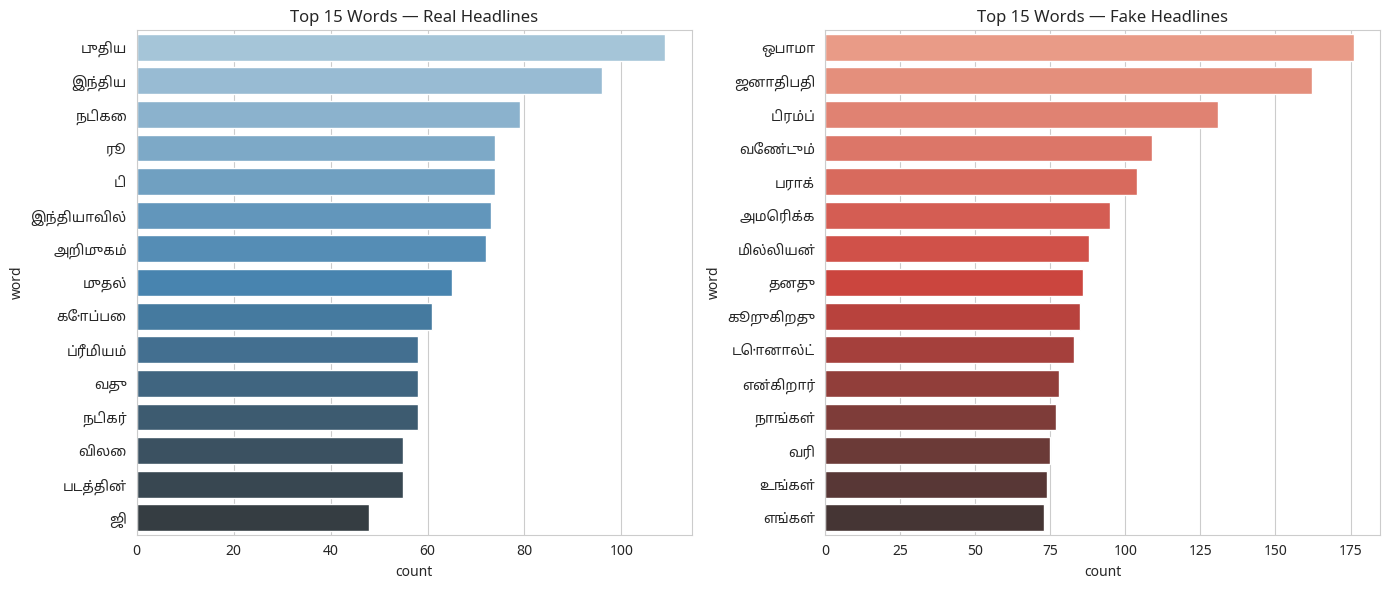

In [ ]:
# Top 15 frequent words: Real vs Fake

def top_words(text_series, n=15):
    words = ' '.join(text_series).split()
    return pd.DataFrame(
        Counter(words).most_common(n),
        columns=['word', 'count']
    )

# Tamil font
plt.rcParams["font.family"] = tamil_font.get_name()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 0 = Real, 1 = Fake
top_real = top_words(df[df['Authenticity'] == 0]['wordcloud_text'])
top_fake = top_words(df[df['Authenticity'] == 1]['wordcloud_text'])
sns.barplot(
    data=top_real,
    x='count',
    y='word',
    hue='word',
    palette='Blues_d',
    legend=False,
    ax=axes[0]
)

axes[0].set_title('Top 15 Words — Real Headlines')

sns.barplot(
    data=top_fake,
    x='count',
    y='word',
    hue='word',
    palette='Reds_d',
    legend=False,
    ax=axes[1]
)

axes[1].set_title('Top 15 Words — Fake Headlines')

plt.tight_layout()
plt.show()

## 5️⃣ Feature Engineering — Train/Test Split & TF-IDF

We split the data (80/20, stratified on the target) and convert the cleaned Tamil headlines into numeric TF-IDF features. scikit-learn's default `\w+` regex tokenizer does not correctly tokenize Tamil script (it splits combining vowel signs away from their base consonants), so we use `token_pattern=r'\S+'` (whitespace-separated tokens) instead — this also keeps the vectorizer picklable for deployment, unlike a custom Python tokenizer function.

In [ ]:
X = df['clean_news']
y = df['Authenticity']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train size:", X_train.shape[0])
print("Test size :", X_test.shape[0])

# scikit-learn's default \w+ regex tokenizer splits Tamil combining vowel
# signs away from their base consonant, corrupting words. \S+ (any
# non-whitespace run) correctly keeps each whitespace-separated Tamil word
# intact, and — unlike a Python callable — is picklable for deployment.
tfidf = TfidfVectorizer(
    token_pattern=r'\S+',
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature matrix shape (train):", X_train_tfidf.shape)

Train size: 4133
Test size : 1034
TF-IDF feature matrix shape (train): (4133, 5000)


## 6️⃣–7️⃣ Model Building & Training

We train several classical ML models on the TF-IDF features and evaluate each one identically, so they can be fairly compared.

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Multinomial Naive Bayes': MultinomialNB(),
    'Linear SVM': LinearSVC(),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42),
}

trained_models = {}
results = []

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    preds = model.predict(X_test_tfidf)

    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    results.append({'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1})
    trained_models[name] = model

    print(f"\n{'='*60}\n{name}\n{'='*60}")
    print(classification_report(y_test, preds, target_names=['Real', 'Fake']))

results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False).reset_index(drop=True)


Logistic Regression
              precision    recall  f1-score   support

        Real       0.92      0.88      0.90       455
        Fake       0.91      0.94      0.92       579

    accuracy                           0.91      1034
   macro avg       0.91      0.91      0.91      1034
weighted avg       0.91      0.91      0.91      1034


Multinomial Naive Bayes
              precision    recall  f1-score   support

        Real       0.94      0.84      0.89       455
        Fake       0.89      0.96      0.92       579

    accuracy                           0.91      1034
   macro avg       0.92      0.90      0.91      1034
weighted avg       0.91      0.91      0.91      1034


Linear SVM
              precision    recall  f1-score   support

        Real       0.90      0.90      0.90       455
        Fake       0.92      0.93      0.92       579

    accuracy                           0.91      1034
   macro avg       0.91      0.91      0.91      1034
weighted avg    

## 8️⃣ Model Evaluation & Comparison

In [ ]:
results_df.style.background_gradient(cmap='Greens', subset=['Accuracy', 'Precision', 'Recall', 'F1-Score'])

,Model,Accuracy,Precision,Recall,F1-Score
0,Linear SVM,0.913926,0.920962,0.925734,0.923342
1,Logistic Regression,0.911992,0.909396,0.936097,0.922553
2,Multinomial Naive Bayes,0.909091,0.886762,0.960276,0.922056
3,Random Forest,0.890716,0.929889,0.870466,0.899197
4,XGBoost,0.860735,0.941176,0.801382,0.865672
5,Decision Tree,0.849130,0.878354,0.848014,0.862917


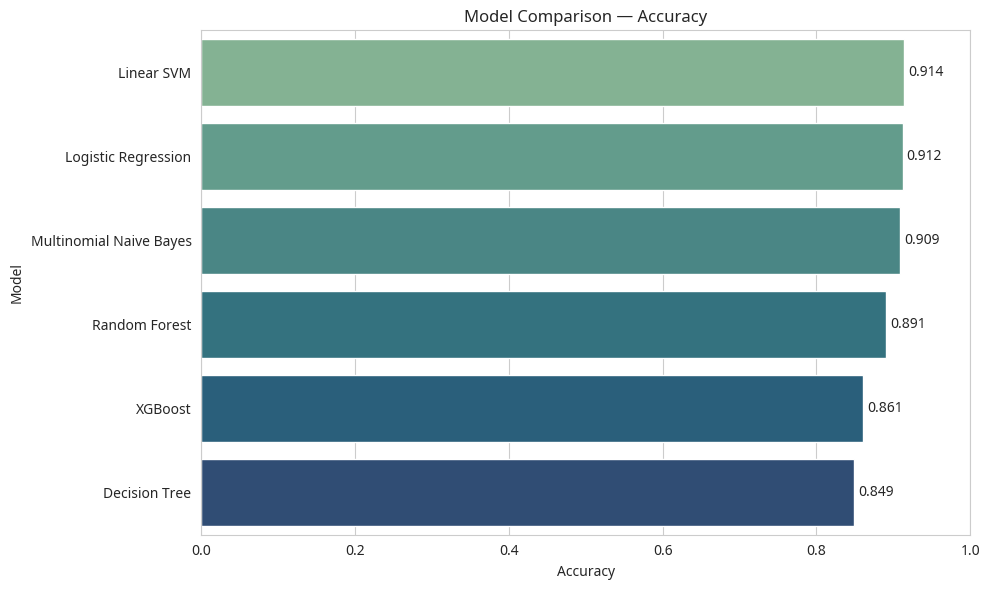

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x='Accuracy', y='Model', hue='Model', palette='crest', legend=False)
plt.title('Model Comparison — Accuracy')
plt.xlim(0, 1)
for i, v in enumerate(results_df['Accuracy']):
    plt.text(v + 0.005, i, f"{v:.3f}", va='center')
plt.tight_layout()
plt.show()

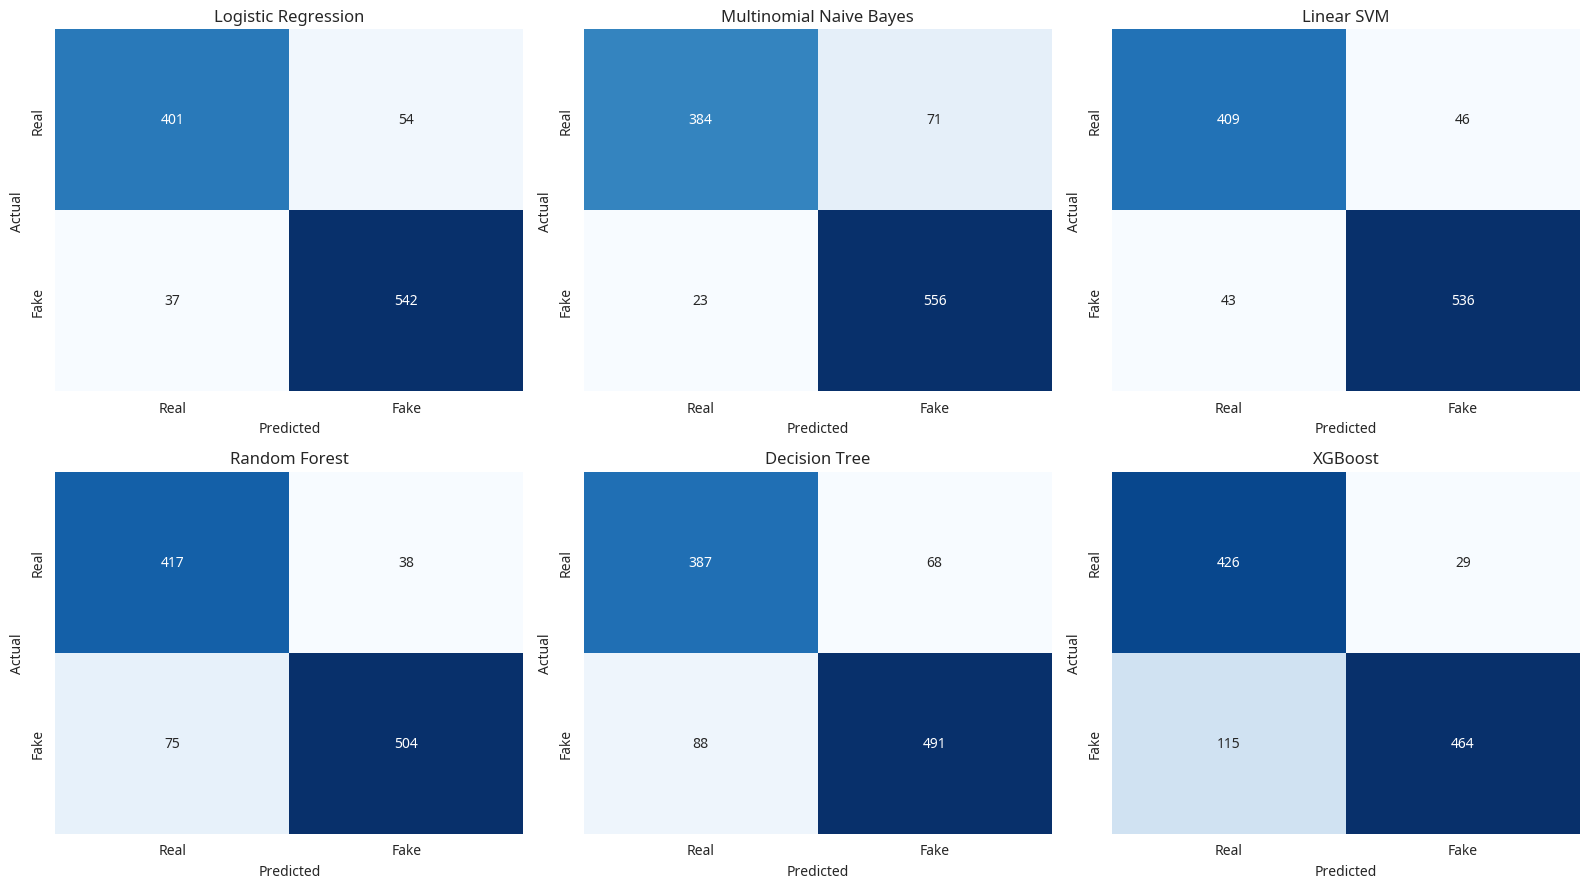

In [ ]:
# Confusion matrices for every model
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (name, model) in zip(axes, trained_models.items()):
    preds = model.predict(X_test_tfidf)
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'], ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [ ]:
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
print(f"🏆 Best model: {best_model_name}  (Accuracy = {results_df.iloc[0]['Accuracy']:.4f})")

🏆 Best model: Linear SVM  (Accuracy = 0.9139)


> **Note:** `LinearSVC` gives fast, strong results but does not natively output probabilities (needed for LIME/SHAP `predict_proba`). If `LinearSVC` wins, either wrap it with `CalibratedClassifierCV` or use `LogisticRegression` for the explainability + deployment sections below — both are shown as good default choices for TF-IDF text classification.

In [ ]:
from sklearn.calibration import CalibratedClassifierCV

# Ensure the deployed model supports predict_proba (needed for LIME/SHAP and the Streamlit app)
if not hasattr(best_model, "predict_proba"):
    print(f"{best_model_name} has no predict_proba — calibrating for probability output...")
    best_model = CalibratedClassifierCV(best_model)
    best_model.fit(X_train_tfidf, y_train)

# Final deployable pipeline: TF-IDF + best model, wrapped together
final_pipeline = Pipeline([
    ('tfidf', tfidf),
    ('clf', best_model)
])
# The Pipeline above reuses the already-fitted tfidf/model — refit end-to-end to be safe
final_pipeline.fit(X_train, y_train)
print("Final pipeline accuracy on test set:", final_pipeline.score(X_test, y_test))

Linear SVM has no predict_proba — calibrating for probability output...
Final pipeline accuracy on test set: 0.9177949709864603


## 9️⃣ Explainability with LIME

LIME (Local Interpretable Model-agnostic Explanations) explains an **individual prediction** by perturbing the input text (dropping words) and seeing how the model's prediction changes. It shows which words pushed the prediction toward *Real* or *Fake*.


Headline: கால்பந்தின் கருப்பு நாளாக மாறிய இந்தோனேசிய கலவரம்
True: Real  |  Predicted: Real


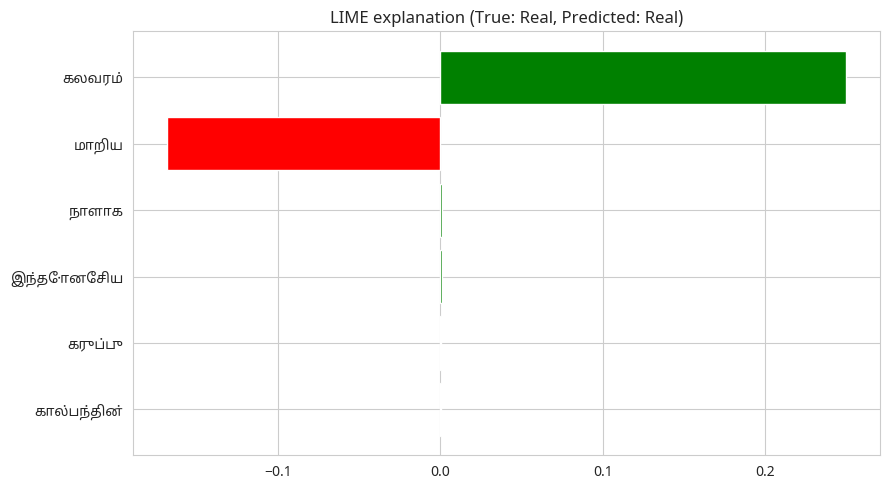


Headline: சாதித்தது போன்ற உணர்வை தருகிறது மனம் திறக்கும் ஹர்திக் பாண்டியா
True: Real  |  Predicted: Real


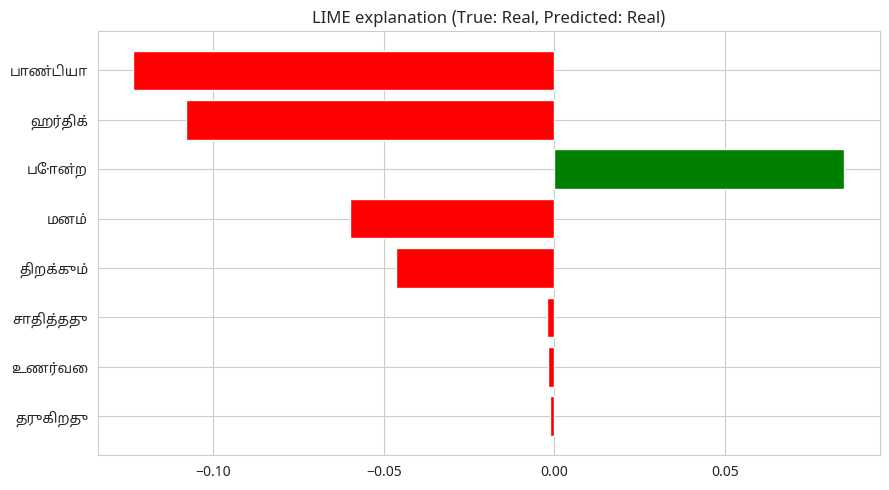


Headline: ரசனைகளைக் கலக்கும் கலக்கி பாய்ஸ்
True: Real  |  Predicted: Real


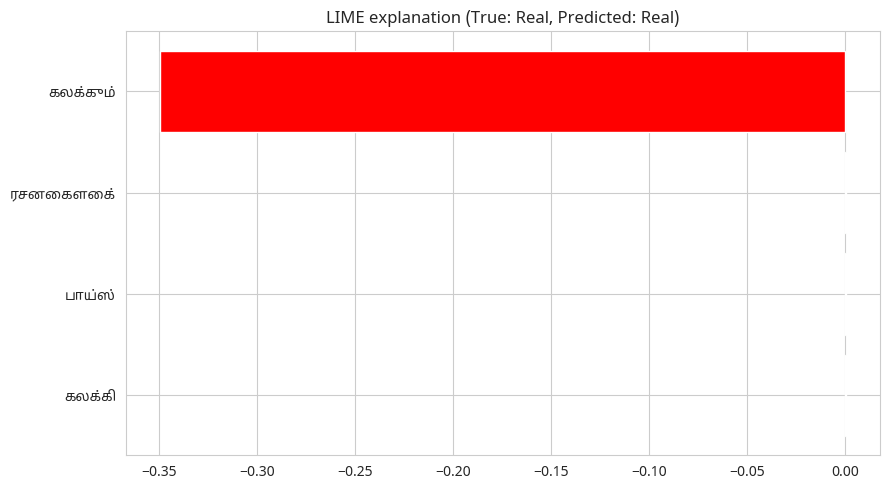

In [ ]:
explainer_lime = LimeTextExplainer(
    class_names=['Real', 'Fake'],
    split_expression=lambda x: x.split()
)

def explain_with_lime(headline_clean_text, num_features=8):
    exp = explainer_lime.explain_instance(
        headline_clean_text,
        final_pipeline.predict_proba,
        num_features=num_features
    )
    return exp


# Explain a few test-set examples
sample_idx = X_test.index[:3]

for idx in sample_idx:
    text = df.loc[idx, 'clean_news']
    true_label = label_map[df.loc[idx, 'Authenticity']]
    pred_label = label_map[final_pipeline.predict([text])[0]]

    print(f"\nHeadline: {text}")
    print(f"True: {true_label}  |  Predicted: {pred_label}")

    exp = explain_with_lime(text)

    # ⭐ ADD THIS LINE HERE
    plt.rcParams["font.family"] = tamil_font.get_name()

    exp.as_pyplot_figure()

    plt.title(
        f"LIME explanation (True: {true_label}, Predicted: {pred_label})"
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# Interactive HTML explanation for a single headline (renders inline in the notebook)
from IPython.display import display, HTML

sample_text = df.loc[sample_idx[0], 'clean_news']
exp = explain_with_lime(sample_text)
display(HTML(exp.as_html()))

## 🔟 Explainability with SHAP

SHAP (SHapley Additive exPlanations) assigns each word a contribution value based on cooperative game theory, giving a more theoretically grounded, globally consistent explanation than LIME. We use SHAP's `Text` masker with the pipeline's `predict_proba` function.

In [ ]:
masker = shap.maskers.Text(tokenizer=r"\s+")

def predict_proba_fn(texts):
    return final_pipeline.predict_proba(list(texts))

explainer_shap = shap.Explainer(predict_proba_fn, masker, output_names=['Real', 'Fake'])

# Explain the same sample headlines
shap_samples = [df.loc[idx, 'clean_news'] for idx in sample_idx]
shap_values = explainer_shap(shap_samples)

In [ ]:
# Visualise SHAP explanation for the 'Real' class, first sample
shap.plots.text(shap_values[0, :, 'Real'])

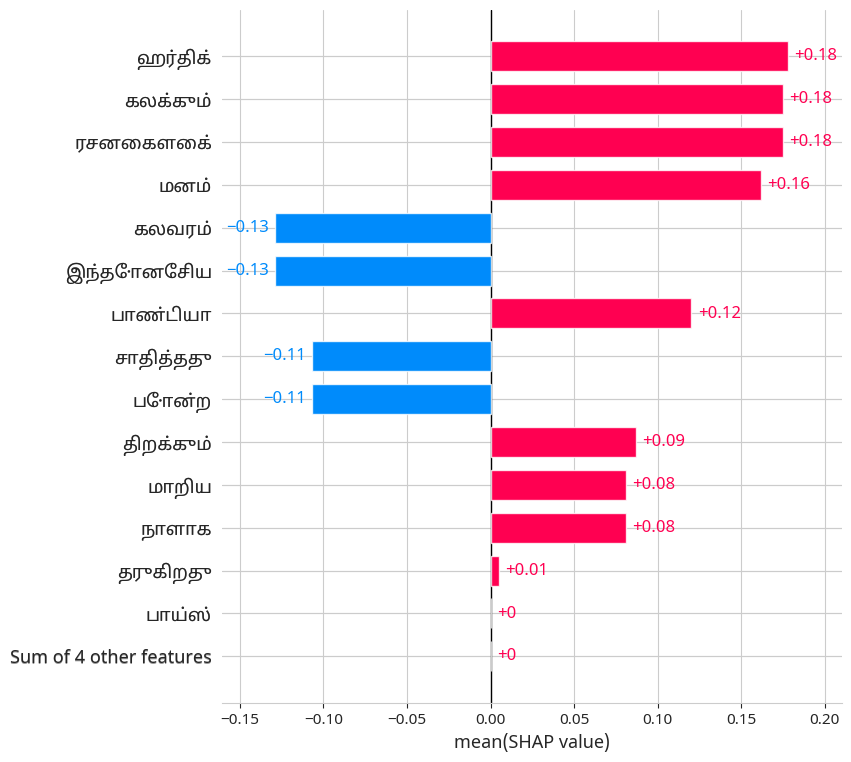

In [ ]:
# Global summary: which words matter most for the 'Real' class across samples
plt.rcParams["font.family"] = tamil_font.get_name()
shap.plots.bar(shap_values[:, :, 'Real'].mean(0), max_display=15)

## 11️⃣ Save the Model Pipeline for Deployment

In [ ]:
joblib.dump(final_pipeline, 'tamil_fake_news_pipeline.pkl')
print("Saved: tamil_fake_news_pipeline.pkl")

# (Optional) download to your machine if running on Colab
try:
    from google.colab import files
    files.download('tamil_fake_news_pipeline.pkl')
except ImportError:
    pass

Saved: tamil_fake_news_pipeline.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12️⃣ Streamlit App — Tamil Fake News Detector

The cell below writes a complete Streamlit app (`app.py`) to disk. It loads `tamil_fake_news_pipeline.pkl`, lets the user type/paste a Tamil headline, predicts **Real / Fake**, and explains the prediction with both **LIME** and **SHAP**.

**To run it:**
- **Locally:** place `app.py` and `tamil_fake_news_pipeline.pkl` in the same folder, then run `streamlit run app.py`
- **From Colab:** use the tunnel cell further below to expose the app with a public URL


In [ ]:
%%writefile app.py
import re
import streamlit as st
import joblib
import shap
from lime.lime_text import LimeTextExplainer
import streamlit.components.v1 as components

st.set_page_config(page_title="Tamil Fake News Detector", page_icon="📰", layout="centered")

# Authenticity=0 -> Real (routine news reporting), Authenticity=1 -> Fake (viral hoax /
# quote-style misinformation) -- verified against actual headline content in the dataset.
LABELS = {0: "Real", 1: "Fake"}
CLASS_NAMES = ["Real", "Fake"]  # order must match sklearn's classes_ = [0, 1]


def clean_tamil_text(text):
    """Same cleaning function used during training -- must match exactly."""
    text = str(text)
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'[a-zA-Z0-9]+', ' ', text)
    text = re.sub(r'[^\u0B80-\u0BFF\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


@st.cache_resource
def load_pipeline():
    return joblib.load("tamil_fake_news_pipeline.pkl")


@st.cache_resource
def load_explainers(_pipeline):
    lime_explainer = LimeTextExplainer(class_names=CLASS_NAMES, split_expression=lambda x: x.split())

    def predict_proba_fn(texts):
        return _pipeline.predict_proba(list(texts))

    masker = shap.maskers.Text(tokenizer=r"\s+")
    shap_explainer = shap.Explainer(predict_proba_fn, masker, output_names=CLASS_NAMES)
    return lime_explainer, shap_explainer


pipeline = load_pipeline()
lime_explainer, shap_explainer = load_explainers(pipeline)

st.title("📰 Tamil Fake News Detector")
st.write(
    "Paste a **Tamil news headline** below. The model predicts whether it is likely "
    "**Real** or **Fake**, and LIME/SHAP highlight which words influenced the decision."
)

headline = st.text_area("Tamil headline", height=100,
                         placeholder="இங்கே தமிழ் செய்தி தலைப்பை உள்ளிடவும்...")

col1, col2, col3 = st.columns([1, 1, 1])
with col1:
    predict_clicked = st.button("🔍 Detect", type="primary", use_container_width=True)
with col2:
    show_lime = st.checkbox("Show LIME explanation", value=True)
with col3:
    show_shap = st.checkbox("Show SHAP explanation", value=True)

if predict_clicked:
    if not headline.strip():
        st.warning("Please enter a Tamil headline first.")
    else:
        cleaned = clean_tamil_text(headline)
        if not cleaned:
            st.error("No Tamil text detected after cleaning -- please enter a Tamil headline.")
        else:
            proba = pipeline.predict_proba([cleaned])[0]
            pred = int(proba.argmax())
            label = LABELS[pred]
            confidence = proba[pred]

            if label == "Real":
                st.success(f"✅ Prediction: **{label}**  (confidence: {confidence:.1%})")
            else:
                st.error(f"⚠️ Prediction: **{label}**  (confidence: {confidence:.1%})")

            st.write(f"P(Real) = {proba[0]:.1%}    |    P(Fake) = {proba[1]:.1%}")

            if show_lime:
                with st.spinner("Generating LIME explanation..."):
                    exp = lime_explainer.explain_instance(
                        cleaned, pipeline.predict_proba, num_features=8)
                    st.subheader("LIME -- why this prediction?")
                    components.html(exp.as_html(), height=400, scrolling=True)

            if show_shap:
                with st.spinner("Generating SHAP explanation..."):
                    shap_values = shap_explainer([cleaned])
                    predicted_class_name = LABELS[pred]
                    html = shap.plots.text(
                        shap_values[0, :, predicted_class_name], display=False)
                    st.subheader("SHAP -- word contribution to prediction")
                    components.html(html, height=250, scrolling=True)

                    st.caption(
                        "Red words push the prediction toward "
                        f"**{predicted_class_name}**; blue words push away from it."
                    )

st.markdown("---")
st.caption(
    "MSc Data Science mini project -- Tamil fake news detection using TF-IDF + "
    "classical ML models, explained with LIME and SHAP."
)

Overwriting app.py


### Running the app from inside Colab (optional, via ngrok)

1. Create a free account at [ngrok.com](https://ngrok.com) and copy your authtoken.
2. Run the cell below, pasting your authtoken when prompted.


In [ ]:
from pyngrok import ngrok
import getpass

authtoken = getpass.getpass("Paste your ngrok authtoken: ")
ngrok.set_auth_token(authtoken)

get_ipython().system_raw('streamlit run app.py --server.port 8501 &')
public_url = ngrok.connect(8501)
print("Streamlit app is live at:", public_url)

Paste your ngrok authtoken: ··········
Streamlit app is live at: NgrokTunnel: "https://penalize-sheep-sizzling.ngrok-free.dev" -> "http://localhost:8501"


---
## Conclusion

- Cleaned and explored 5,000+ Tamil news headlines, comparing Real vs Fake patterns by category and word usage.
- Represented Tamil text with a custom whitespace-tokenised TF-IDF (n-grams 1–2).
- Trained and compared **6 ML models** (Logistic Regression, Naive Bayes, Linear SVM, Random Forest, Decision Tree, XGBoost) on accuracy, precision, recall and F1-score.
- Explained individual predictions with **LIME** and **SHAP**, showing which Tamil words drove each Real/Fake decision.
- Packaged the best model into a deployable **Streamlit app** for interactive fake-news detection.

**Possible extensions:** try Tamil-specific transformer embeddings (e.g. IndicBERT/MuRIL) instead of TF-IDF, add the `English Version` column as an auxiliary feature, or expand the stopword list / add stemming for better preprocessing.
